# Spoken Grammar Scoring Engine
SHL Hiring Assessment 2026, Anuj Dev Singh

The task: given a 45-60 s recording of someone speaking English, predict the grammar score (0 to 5, in steps of
0.5) that a human rater gave using SHL's rubric. There are 769 scored training clips and 216 test clips. The
leaderboard combines RMSE and Pearson correlation.

The most important thing I found: the same speakers appear in many training clips, while every test speaker is
new. My first cross-validation mixed one speaker's clips across training and validation, so models could
partly score a clip by recognising the voice. Once I validated on folds where each voice is either in training
or in validation (speaker-grouped CV), the models I chose moved the leaderboard the right way again, and the best
public score went from 0.3655 to 0.3507.

The final engine combines five models, all chosen on speaker-grouped CV:
1. Frozen Whisper-large-v3 and WavLM-large audio features (late layers) with a Ridge regression.
2. DeBERTa-v3-large fine-tuned on the Whisper transcripts.
3. Frozen Qwen2.5-7B-Instruct reading the transcript, with a Ridge regression on its hidden states.
4. An adapter grader: a small network on frozen Whisper frames.
5. Frozen DeBERTa-v3 / RoBERTa transcript embeddings plus 42 fluency and grammar features (weight 0 in e019).

A non-negative linear stack combines them, and predictions for clips with the same voice are partly averaged.

My two final submissions are e019 (best cross-validation) and e016 (best public score, the same engine without
models 2 and 4).

Contents: 1 Data, 2 Preprocessing, 3 The speaker finding, 4 Final engine, 5 Results (training RMSE, CV RMSE,
Pearson), 6 Visualisations, 7 CV vs leaderboard, 8 What did not work, 9 Reproduce.

The competition data is for competition use only, so this notebook only shows aggregate numbers and plots. It
never prints audio, transcripts or per-file rows.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from cv import DATA, pearson, rmse  # noqa: E402
from grouped import metric  # noqa: E402

CACHE = ROOT / "cache"
FINAL, ALT = "e019", "e016"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREY, GREEN = "#2f6db5", "#e07b39", "#8c8c8c", "#3a9a5b"

## 1. Data
The labels lean towards higher scores. 37 clips are scored 0, below the rubric's lowest level of 1. When I checked
them they turned out to be invalid recordings (high no-speech probability, low ASR confidence). The test set has
none of these, so the final models learn from the 732 clips scored 1-5. The test clips are also shorter (median
45 s against 60 s) and a bit quieter.

train clips 769, test clips 216
label mean 3.313, std 1.238, clips labelled 0: 37


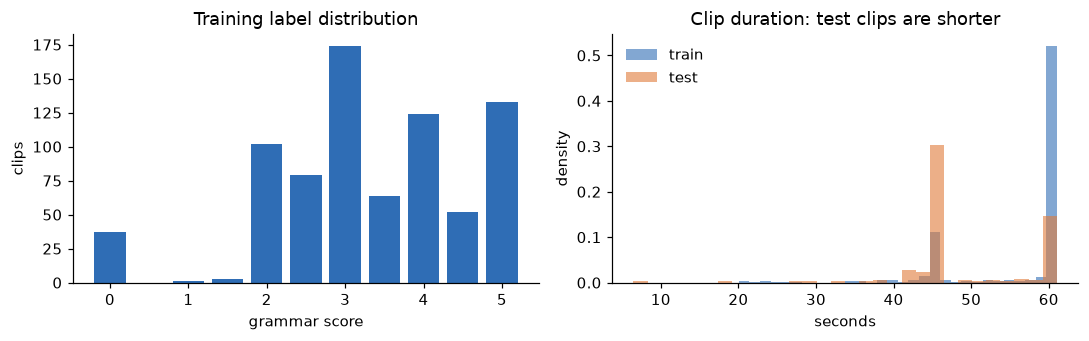

In [2]:
train = pd.read_csv(DATA / "train.csv")
audit = pd.read_csv(CACHE / "audit_audio.csv")
y_all = train.label
print(f"train clips {len(train)}, test clips {len(pd.read_csv(DATA / 'test.csv'))}")
print(f"label mean {y_all.mean():.3f}, std {y_all.std(ddof=0):.3f}, clips labelled 0: {(y_all == 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
vc = y_all.value_counts().sort_index()
ax[0].bar(vc.index, vc.values, width=0.4, color=BLUE)
ax[0].set(title="Training label distribution", xlabel="grammar score", ylabel="clips")
for s, c in [("train", BLUE), ("test", ORANGE)]:
    ax[1].hist(audit[audit.split == s].duration, bins=30, alpha=0.6, color=c, label=s, density=True)
ax[1].set(title="Clip duration: test clips are shorter", xlabel="seconds", ylabel="density")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 2. Preprocessing
All files are already 16 kHz mono, with no clipping and no duplicates. I normalise loudness (RMS) to about
-20 dBFS so the quieter test clips match train, and I do not trim silence, because pauses and hesitations are part
of what the rater hears. Whisper's encoder reads at most 30 s, so clips are cut into 30 s windows and the pooled
vectors are averaged by length. Transcripts come from faster-whisper large-v3, prompted so it keeps fillers and
restarts.

## 3. The speaker finding
I turned each clip into a voice vector with a speaker-verification model (ECAPA-TDNN, SpeechBrain) and compared
clips by cosine similarity, where 1.0 means the same voice. Train clips almost always have a near-identical voice
elsewhere in train. Test clips do not have one in train.

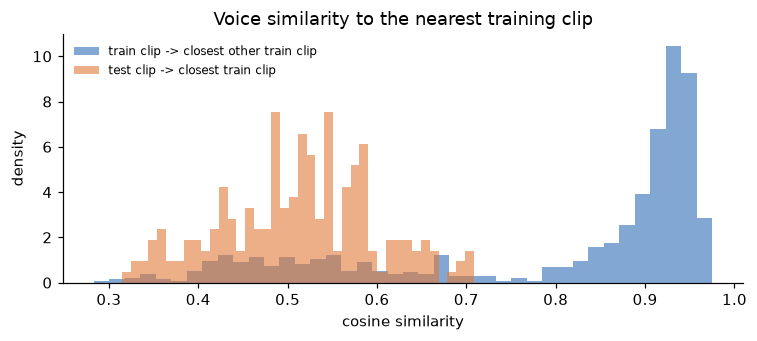

median nearest similarity: train 0.91, test 0.52


In [3]:
E = np.load(CACHE / "speaker_emb.npy")
so = pd.read_csv(CACHE / "speaker_order.csv")
tr_m, te_m = (so.split == "train").to_numpy(), (so.split == "test").to_numpy()
S = E @ E.T
np.fill_diagonal(S, -1)
nn_train = S[tr_m][:, tr_m].max(1)
nn_test = S[te_m][:, tr_m].max(1)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(nn_train, bins=40, alpha=0.6, color=BLUE, density=True, label="train clip -> closest other train clip")
ax.hist(nn_test, bins=40, alpha=0.6, color=ORANGE, density=True, label="test clip -> closest train clip")
ax.set(title="Voice similarity to the nearest training clip", xlabel="cosine similarity", ylabel="density")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
print(f"median nearest similarity: train {np.median(nn_train):.2f}, test {np.median(nn_test):.2f}")

Within one voice the score barely changes (standard deviation 0.17, against 0.97 overall), and my random folds
split 187 of the 208 repeated voices across training and validation. So a model could score a validation clip
partly by recognising the voice, which it cannot do on the test set. Re-scoring the same models with
speaker-grouped folds shows how much this inflated CV (RMSE on the 1-5 clips):

| Model | Random folds | Speaker-grouped folds |
|---|---|---|
| Frozen Whisper + WavLM, Ridge | 0.529 | 0.622 |
| Transcript features, Ridge | 0.763 | 0.781 |

The audio model leaned on voice memory; the text model, which cannot hear the voice, barely moved. From here on,
every model, its settings and the stack weights are chosen on speaker-grouped folds (StratifiedGroupKFold, 5
folds, voices clustered at cosine 0.7). Ridge's regularisation is also picked with an inner speaker-grouped CV,
because its built-in leave-one-out choice still sees the left-out clip's voice in training.

## 4. Final engine
| Model | What it captures | How it is trained |
|---|---|---|
| Audio Ridge | Whisper-large-v3 layers 29-32 + WavLM-large layers 17-24, mean and std over time | Ridge, alpha by inner grouped CV |
| Fine-tuned DeBERTa (e019) | DeBERTa-v3-large reading the Whisper transcript, mean pooling, linear head | 4 fixed epochs, lr 1e-5, 3 seeds, 5 fold models |
| Qwen-7B transcript states | Qwen2.5-7B-Instruct reading a rubric prompt + transcript, mean of layers 16/19/22 | frozen, Ridge on top |
| Adapter grader (e019) | frozen Whisper frames (layers 16/22/27/32) -> small per-layer adapters, one Transformer layer, mean + std pooling | 20 s crops + span masking, 15 epochs, 3 seeds, 5 fold models |
| Text encoders + features | frozen DeBERTa-v3 / RoBERTa embeddings + 42 fluency and grammar features | Ridge |
| Stack | how much to trust each model | non-negative linear regression on grouped out-of-fold predictions |

Same-voice smoothing: test clips whose voice vectors match (56 of 216 clips) are pulled halfway towards their
voice's mean prediction. On grouped CV this improves the score by about 0.005.

The leaderboard formula (found by another competitor and consistent with all my submissions) is
0.6 x RMSE + 0.4 x (1 - Pearson). I report it as "score" below; lower is better.

## 5. Results
Training RMSE (in-sample) means refitting the Ridge models and the stack on all 732 scored clips and scoring
those same clips, so it is optimistic by design. The fine-tuned DeBERTa and the adapter have no all-data model
(their test prediction averages the 5 fold models), so their out-of-fold predictions stand in there. CV RMSE and
Pearson come from speaker-grouped cross-validation: every clip is predicted by models that never heard its voice.

In [4]:
rows = []
for exp in (ALT, FINAL):
    j = json.load(open(CACHE / f"final_{exp}.json"))
    for n, v in j["branch_cv"].items():
        rows.append(dict(engine=exp, model=n, weight=round(j["weights"][n], 3), cv_rmse=v["rmse"], cv_pearson=v["pearson"],
                         score=v["metric"]))
    rows.append(dict(engine=exp, model="STACK", weight=np.nan, cv_rmse=j["grouped_rmse"], cv_pearson=j["grouped_pearson"],
                     score=j["grouped_metric"], train_rmse=j["train_rmse"]))
res = pd.DataFrame(rows)
y1 = np.load(CACHE / f"final_{FINAL}.npz")["y"]
base = y1[y1 > 0].std()
print(f"mean baseline (predict the train mean), 1-5 clips: RMSE {base:.4f}, Pearson 0, score {0.6 * base + 0.4:.4f}\n")
print(res.rename(columns={"cv_rmse": "CV RMSE", "cv_pearson": "CV Pearson", "train_rmse": "Training RMSE (in-sample)"})
      .round(4).to_string(index=False))

mean baseline (predict the train mean), 1-5 clips: RMSE 1.0137, Pearson 0, score 1.0082

engine            model  weight  CV RMSE  CV Pearson  score  Training RMSE (in-sample)
  e016            audio   0.566   0.5786      0.8212 0.4187                        NaN
  e016         enc_text   0.245   0.5991      0.8069 0.4367                        NaN
  e016           qwen7b   0.306   0.6031      0.8048 0.4399                        NaN
  e016            STACK     NaN   0.5251      0.8561 0.3726                     0.3673
  e019            audio   0.271   0.5786      0.8212 0.4187                        NaN
  e019         enc_text   0.000   0.5991      0.8069 0.4367                        NaN
  e019           qwen7b   0.212   0.6031      0.8048 0.4399                        NaN
  e019          ft_text   0.330   0.5774      0.8230 0.4172                        NaN
  e019 adapter5_whisper   0.269   0.5919      0.8138 0.4296                        NaN
  e019            STACK     NaN   0.5172 

| | Training RMSE (in-sample) | CV RMSE (grouped) | CV Pearson | CV score | Public LB |
|---|---|---|---|---|---|
| e016 | 0.367 | 0.525 | 0.856 | 0.373 | 0.3507 |
| e019 | 0.447 | 0.517 | 0.861 | 0.366 | 0.3532 |

e019 is better than e016 on all 5 grouped folds (bootstrap 95% interval of the gain 0.0005 to 0.013). On the public
leaderboard, which uses about 70 clips, e016 is ahead by 0.0025, which is well inside the noise of that small
sample.

## 6. Visualisations

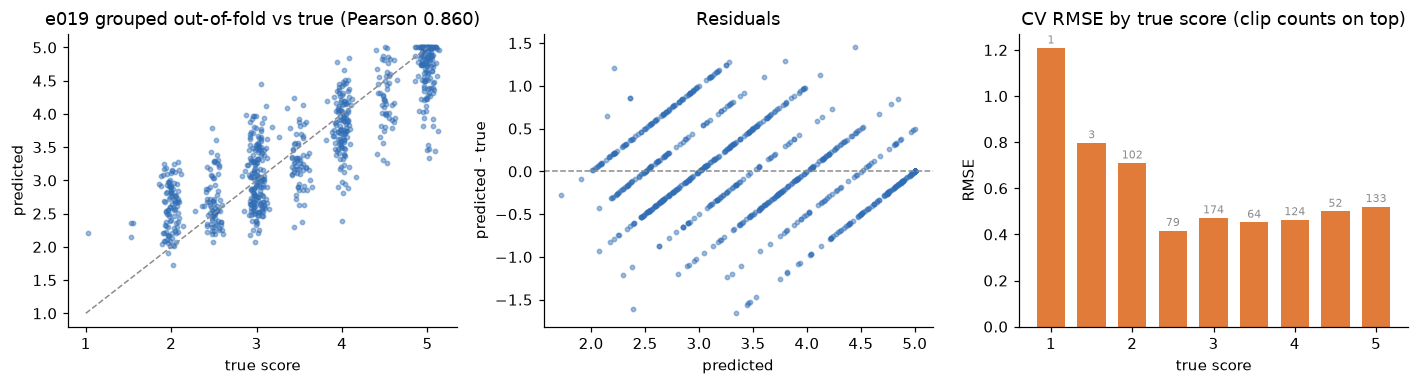

In [5]:
d = np.load(CACHE / f"final_{FINAL}.npz", allow_pickle=True)
y, st, fold = d["y"], d["stack_oof"], d["fold"]
m = y > 0
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
jit = np.random.default_rng(0).normal(0, 0.06, m.sum())
ax[0].scatter(y[m] + jit, st[m], s=8, alpha=0.45, color=BLUE)
ax[0].plot([1, 5], [1, 5], color=GREY, lw=1, ls="--")
ax[0].set(title=f"e019 grouped out-of-fold vs true (Pearson {pearson(y[m], st[m]):.3f})", xlabel="true score",
          ylabel="predicted")
ax[1].scatter(st[m], st[m] - y[m], s=8, alpha=0.45, color=BLUE)
ax[1].axhline(0, color=GREY, lw=1, ls="--")
ax[1].set(title="Residuals", xlabel="predicted", ylabel="predicted - true")
g = pd.DataFrame(dict(y=y[m], e2=(st[m] - y[m]) ** 2)).groupby("y")
by = g.e2.mean().pow(0.5)
ax[2].bar(by.index, by.values, width=0.35, color=ORANGE)
for xv, n in g.size().items():
    ax[2].text(xv, by[xv] + 0.02, str(n), ha="center", fontsize=7, color=GREY)
ax[2].set(title="CV RMSE by true score (clip counts on top)", xlabel="true score", ylabel="RMSE")
plt.tight_layout()
plt.show()

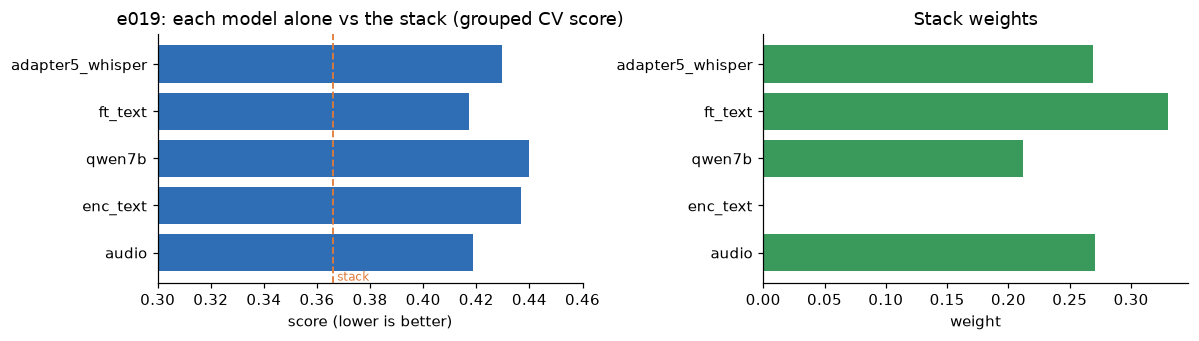

In [6]:
j = json.load(open(CACHE / f"final_{FINAL}.json"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
names = list(j["branch_cv"])
ax[0].barh(names, [j["branch_cv"][n]["metric"] for n in names], color=BLUE)
ax[0].axvline(j["grouped_metric"], color=ORANGE, ls="--", lw=1.2)
ax[0].text(j["grouped_metric"], -0.6, " stack", color=ORANGE, fontsize=8)
ax[0].set(title="e019: each model alone vs the stack (grouped CV score)", xlabel="score (lower is better)", xlim=(0.3, 0.46))
ax[1].barh(names, [j["weights"][n] for n in names], color=GREEN)
ax[1].set(title="Stack weights", xlabel="weight")
plt.tight_layout()
plt.show()

Fine-tuning curves of the DeBERTa transcript model: validation RMSE per epoch, averaged over the 3 seeds of each
fold. The 4 epochs were fixed in advance and never picked by looking at these curves.

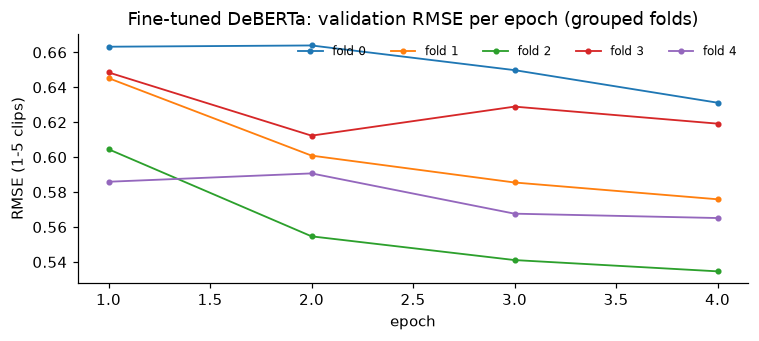

In [7]:
logs = pd.concat([pd.read_csv(CACHE / "ft_text_run" / "ft_text" / f"log_fold{k}.csv") for k in range(5)])
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, gk in logs.groupby("fold"):
    c = gk.groupby("epoch").val_rmse_1to5.mean()
    ax.plot(c.index, c.values, marker="o", ms=3, lw=1.2, label=f"fold {k}")
ax.set(title="Fine-tuned DeBERTa: validation RMSE per epoch (grouped folds)", xlabel="epoch", ylabel="RMSE (1-5 clips)")
ax.legend(frameon=False, ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

## 7. CV vs leaderboard
With random folds, every model that used voice memory looked better in CV but did worse on the leaderboard
(e011-e013). With speaker-grouped folds, the first engine I built (e016) was my best public score.

In [8]:
lb = pd.DataFrame([
    ("e000", "train mean", "-", 1.0050), ("e002", "frozen Whisper-large + WavLM + Ridge", "random", 0.4165),
    ("e006", "+ fine-tuned WavLM", "random", 0.3985), ("e007", "+ transcript features", "random", 0.3865),
    ("e009", "+ fine-tuned audio LLM", "random", 0.3655), ("e011", "+ adapter grader", "random", 0.3742),
    ("e013", "adapter + pseudo-labels", "random", 0.3757), ("e016", "speaker-grouped engine", "grouped", 0.3507),
    ("e019", "e016 + fine-tuned DeBERTa + grouped adapter", "grouped", 0.3532)],
    columns=["id", "what", "folds used to choose it", "public LB"])
print(lb.to_string(index=False))

  id                                        what folds used to choose it  public LB
e000                                  train mean                       -     1.0050
e002        frozen Whisper-large + WavLM + Ridge                  random     0.4165
e006                          + fine-tuned WavLM                  random     0.3985
e007                       + transcript features                  random     0.3865
e009                      + fine-tuned audio LLM                  random     0.3655
e011                            + adapter grader                  random     0.3742
e013                     adapter + pseudo-labels                  random     0.3757
e016                      speaker-grouped engine                 grouped     0.3507
e019 e016 + fine-tuned DeBERTa + grouped adapter                 grouped     0.3532


## 8. What did not work
Each idea was judged by the same rule: better on at least 4 of 5 grouped folds, with a bootstrap 95% interval of
the gain above 0.

| Idea | Result on speaker-grouped CV |
|---|---|
| Fine-tuned WavLM-large (grouped folds) | alone 0.459; adds nothing to the stack (1/5 folds) |
| Length-matched 40-50 s crop augmentation for the audio Ridge | worse alone (0.423 vs 0.419) and in the stack, even on short clips |
| Second, literal transcript (wav2vec2 CTC, no language model) + fine-tuned DeBERTa | alone 0.437; no gain in the stack |
| Qwen2.5-7B fine-tuned on transcripts (QLoRA) | alone 0.439; no gain in the stack |
| Qwen3-4B transcript states | no gain over Qwen2.5-7B |
| Removing the voice component from audio features | collapses the signal |
| Speed / pitch / noise augmentation | not tried: speed changes fluency, which raters partly score |
| Earlier, on random folds: SVR, PCA, w2v-BERT 2.0, zero-shot audio-LLM judge, short-clip adapter, importance weighting, per-clip normalisation | no gain |

Limitations: predictions are squeezed towards the middle (scores 1.0-1.5 have only 4 training clips), short clips
are harder, Whisper cleans up some grammar errors before the text models see them, and with only about 585
training clips per fold the bigger fine-tuned models stop adding information.

## 9. Reproduce
```
python src/audit.py; python src/cv.py                 # data checks, fixed folds
python src/speaker.py; python src/speaker_check.py    # voice vectors, speaker-grouped folds (cache/folds_speaker.csv)
# GPU stages on Kaggle T4 x2: run the builder, then kaggle kernels push -p kaggle/<stage> --accelerator NvidiaTeslaT4
kaggle/build_embed.sh         # frozen Whisper / WavLM embeddings -> cache/emb
kaggle/build_transcribe.sh    # transcripts -> cache/transcripts.jsonl
kaggle/build_llm_text.sh      # Qwen2.5-7B transcript states -> cache/llm_text_run
kaggle/build_adapter5.sh      # adapter grader on grouped folds -> cache/adapter5_run
kaggle/build_ft_text.sh       # fine-tuned DeBERTa on grouped folds -> cache/ft_text_run
python src/features.py; python src/text_emb.py        # transcript features, frozen text embeddings
python src/final_grouped.py --exp e016
python src/final_grouped.py --exp e019 --fold_models cache/ft_text_run/ft_text,cache/adapter5_run/adapter5_whisper
```
Both final commands rebuild the submitted files exactly from the cached model outputs. This notebook only reads
cached results.